# Lesson 3 — The training loop: train your own agent

In this lesson you learn:

1. What one piece of experience (a **transition**) is.
2. **Replay memory**: why the agent learns from old, random experience.
3. The **Bellman target**: the "correct answer" that the network learns.
4. **Loss** and one **gradient step**: how the weights change.
5. The full loop of `train.py`. You train an agent in about **5 minutes**.

Source file for this lesson: `train.py`. Do Lessons 1 and 2 first.

---

**🇻🇳 Bài 3 — Vòng lặp huấn luyện: tự huấn luyện agent của bạn**

Trong bài này bạn học:

1. Một mẩu kinh nghiệm (một **transition** — bước chuyển) là gì.
2. **Bộ nhớ phát lại (replay memory)**: tại sao agent học từ kinh nghiệm cũ, chọn ngẫu nhiên.
3. **Mục tiêu Bellman (Bellman target)**: "đáp án đúng" mà mạng học theo.
4. **Hàm mất mát (loss)** và một **bước gradient**: trọng số thay đổi như thế nào.
5. Toàn bộ vòng lặp của `train.py`. Bạn huấn luyện một agent trong khoảng **5 phút**.

File mã nguồn của bài này: `train.py`. Hãy làm Bài 1 và Bài 2 trước.

In [1]:
# Setup: find the project folder, so that "import src..." works from this notebook.
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
print("Project folder:", ROOT)

Project folder: /Users/phuonghqh/Documents/working/Tetris-deep-Q-learning-pytorch


In [2]:
import random
import time
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from src.tetris import Tetris
from src.deep_q_network import DeepQNetwork
from src.model_io import load_model
from nb_utils import evaluate, random_policy, greedy_policy, feature_sweep

## Part 1 — One transition

After each move, the agent stores 4 things: `[state, reward, next_state, done]`.

- `state` = the 4 features of the board **before** the move
- `reward` = the reward of the move
- `next_state` = the 4 features of the afterstate that the agent chose
- `done` = `True` if the move ended the game

---

**🇻🇳 Phần 1 — Một transition**

Sau mỗi nước đi, agent lưu 4 thứ: `[state, reward, next_state, done]`.

- `state` = 4 đặc trưng của bàn chơi **trước** nước đi
- `reward` = phần thưởng của nước đi
- `next_state` = 4 đặc trưng của afterstate mà agent đã chọn
- `done` = `True` nếu nước đi làm kết thúc ván

In [3]:
torch.manual_seed(123)
random.seed(123)
env = Tetris()
model = DeepQNetwork()

state = env.reset()
actions, states = zip(*env.get_next_states().items())
states = torch.stack(states)
with torch.no_grad():
    index = torch.argmax(model(states)[:, 0]).item()
next_state = states[index]
reward, done = env.step(actions[index], render=False)

print("state     :", state.tolist(), "(empty board)")
print("action    :", actions[index])
print("reward    :", reward)
print("next_state:", next_state.tolist())
print("done      :", done)

state     : [0.0, 0.0, 0.0, 0.0] (empty board)
action    : (0, 2)
reward    : 1
next_state: [0.0, 2.0, 2.0, 6.0]
done      : False


## Part 2 — Replay memory

`train.py` keeps the last 30,000 transitions in a `deque` (a list with a maximum length).
When the deque is full, the oldest item goes out. For each training step, the agent takes **512 random** transitions.

**Why random?** Moves of one game are very similar. If the network learns only from the last moves,
it forgets old lessons. Random samples from many games give a balanced lesson.

---

**🇻🇳 Phần 2 — Bộ nhớ phát lại (replay memory)**

`train.py` giữ 30.000 transition gần nhất trong một `deque` (một danh sách có độ dài tối đa).
Khi deque đầy, phần tử cũ nhất bị loại ra. Ở mỗi bước huấn luyện, agent lấy **512 transition ngẫu nhiên**.

**Tại sao ngẫu nhiên?** Các nước đi trong cùng một ván rất giống nhau. Nếu mạng chỉ học từ những nước đi mới nhất,
nó sẽ quên các bài học cũ. Mẫu ngẫu nhiên từ nhiều ván cho một bài học cân bằng.

In [4]:
demo = deque(maxlen=5)
for i in range(8):
    demo.append(f"move {i}")
print("memory (max 5):", list(demo))
print("random sample of 3:", random.sample(list(demo), 3))

memory (max 5): ['move 3', 'move 4', 'move 5', 'move 6', 'move 7']
random sample of 3: ['move 4', 'move 7', 'move 6']


## Part 3 — The Bellman target

The network must learn the **value** of a board: "how much reward will I get from here?".
We do not know the true value. So we use this target:

- if the game ended: `target = reward`
- else: `target = reward + gamma × value(next_state)`

**gamma (γ = 0.99)** is the **discount factor**: a future reward counts a little less than a reward now.

When the game ends, the target has no future part. So boards that end the game get a low value.
**That is the real penalty for game over.**

`train.py` writes this as `reward if done else reward + gamma * prediction`.
We write the same rule with numbers: `reward + gamma * value * (1 - done)`.

---

**🇻🇳 Phần 3 — Mục tiêu Bellman**

Mạng phải học **giá trị** của một bàn chơi: "từ đây tôi sẽ nhận được bao nhiêu phần thưởng?".
Ta không biết giá trị thật. Vì vậy ta dùng mục tiêu này:

- nếu ván đã kết thúc: `target = reward`
- nếu không: `target = reward + gamma × value(next_state)`

**gamma (γ = 0.99)** là **hệ số chiết khấu (discount factor)**: phần thưởng trong tương lai được tính ít hơn một chút so với phần thưởng hiện tại.

Khi ván kết thúc, mục tiêu không có phần tương lai. Vì vậy những bàn chơi làm kết thúc ván nhận giá trị thấp.
**Đó là hình phạt thật sự khi thua.**

`train.py` viết điều này là `reward if done else reward + gamma * prediction`.
Ta viết cùng quy tắc đó bằng số: `reward + gamma * value * (1 - done)`.

In [6]:
gamma = 0.99
rewards     = torch.tensor([[1.], [11.], [1.]])
next_values = torch.tensor([[50.], [40.], [30.]])   # the network's guess for each next_state
dones       = torch.tensor([[0.], [0.], [1.]])      # the 3rd move ended the game
targets = rewards + gamma * next_values * (1 - dones)
print(targets)

tensor([[50.5000],
        [50.6000],
        [ 1.0000]])


## Part 4 — Loss and one gradient step

- **Loss:** a number that tells how wrong the network is. We use **MSE** (mean squared error):
  the average of `(prediction − target)²`.
- `optimizer.zero_grad()` removes the old gradients.
- `loss.backward()` calculates, for each weight, how it changes the loss (**backpropagation**).
- `optimizer.step()` changes the weights a little, to make the loss smaller (**Adam** optimizer).

We collect transitions from 5 random games, calculate the targets one time, and do 30 steps.
The loss goes down, but not at every step. Small jumps are normal.

---

**🇻🇳 Phần 4 — Hàm mất mát và một bước gradient**

- **Loss (mất mát):** một con số cho biết mạng sai bao nhiêu. Ta dùng **MSE** (sai số bình phương trung bình):
  trung bình của `(dự đoán − mục tiêu)²`.
- `optimizer.zero_grad()` xóa các gradient cũ.
- `loss.backward()` tính, cho mỗi trọng số, nó làm loss thay đổi thế nào (**lan truyền ngược — backpropagation**).
- `optimizer.step()` thay đổi trọng số một chút để loss nhỏ hơn (bộ tối ưu **Adam**).

Ta thu thập transition từ 5 ván ngẫu nhiên, tính mục tiêu một lần, và chạy 30 bước.
Loss giảm dần, nhưng không phải bước nào cũng giảm. Những bước nhảy nhỏ là bình thường.

In [7]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

memory = []
for _ in range(5):
    state, done = env.reset(), False
    while not done:
        actions, states = zip(*env.get_next_states().items())
        i = random.randrange(len(actions))
        reward, done = env.step(actions[i], render=False)
        memory.append([state, reward, states[i], done])
        state = states[i]

s, r, ns, d = zip(*memory)
s, ns = torch.stack(s), torch.stack(ns)
r = torch.tensor(r, dtype=torch.float32)[:, None]
d = torch.tensor(d, dtype=torch.float32)[:, None]
with torch.no_grad():
    y = r + gamma * model(ns) * (1 - d)

print("transitions:", len(memory))
for step in range(30):
    loss = criterion(model(s), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 3 == 0 or step == 29:
        print(f"step {step:>2}: loss = {loss.item():.3f}")

transitions: 108
step  0: loss = 4.838
step  3: loss = 4.498
step  6: loss = 3.923
step  9: loss = 4.179
step 12: loss = 3.666
step 15: loss = 3.556
step 18: loss = 3.670
step 21: loss = 3.445
step 24: loss = 3.426
step 27: loss = 3.430
step 29: loss = 3.324


In real training the targets change too, because the network makes them (this is **bootstrapping**).
So in RL, the loss is not a good progress measure. We measure the game results: pieces, lines, score.

## Part 5 — The full training loop

This is the loop of `train.py`, with 3 small changes:

1. No game window (`render=False`), so it is much faster.
2. A limit of `max_pieces` per game. When a game reaches the limit, we stop it, but we do **not** mark it as `done`.
   The board was not lost, so its future value is still real. (RL calls this **truncation**, not termination.)
3. The target uses the `(1 - done)` form from Part 3.

**1 epoch = 1 game = 1 training step.** Training starts when the memory has 3,000 transitions.

⏱ This cell takes about **5 minutes**. For a quick test, set `num_epochs` to 1000 (the agent will learn less).

---

🇻🇳 Trong huấn luyện thật, mục tiêu cũng thay đổi, vì chính mạng tạo ra chúng (đây gọi là **bootstrapping**).
Vì vậy trong RL, loss không phải là thước đo tiến bộ tốt. Ta đo kết quả chơi: số mảnh, số hàng, điểm.

**🇻🇳 Phần 5 — Toàn bộ vòng lặp huấn luyện**

Đây là vòng lặp của `train.py`, với 3 thay đổi nhỏ:

1. Không có cửa sổ trò chơi (`render=False`), nên nhanh hơn nhiều.
2. Giới hạn `max_pieces` mảnh mỗi ván. Khi một ván đạt giới hạn, ta dừng nó, nhưng **không** đánh dấu là `done`.
   Bàn chơi chưa thua, nên giá trị tương lai của nó vẫn có thật. (RL gọi đây là **cắt ngắn — truncation**, không phải **kết thúc — termination**.)
3. Mục tiêu dùng dạng `(1 - done)` từ Phần 3.

**1 epoch = 1 ván = 1 bước huấn luyện.** Huấn luyện bắt đầu khi bộ nhớ có 3.000 transition.

⏱ Ô này chạy khoảng **5 phút**. Để thử nhanh, đặt `num_epochs` thành 1000 (agent sẽ học được ít hơn).

In [8]:
HP = dict(lr=1e-3, gamma=0.99, batch_size=512, replay_memory_size=30000,
          initial_epsilon=1.0, final_epsilon=1e-3, num_decay_epochs=2000, num_epochs=3000,
          max_pieces=500)

In [10]:
torch.manual_seed(123)
random.seed(123)
env = Tetris()
model = DeepQNetwork()
optimizer = torch.optim.Adam(model.parameters(), lr=HP["lr"])
criterion = nn.MSELoss()
memory = deque(maxlen=HP["replay_memory_size"])
history = []                       # one row per game: (epoch, score, pieces, lines)

state = env.reset()
epoch, start = 0, time.time()
while epoch < HP["num_epochs"]:
    # 1. Epsilon: the probability of a random move (train.py lines 66-67)
    epsilon = HP["final_epsilon"] + max(HP["num_decay_epochs"] - epoch, 0) * (
        HP["initial_epsilon"] - HP["final_epsilon"]) / HP["num_decay_epochs"]

    # 2. Choose an action: random, or the afterstate with the highest value (lines 70-84)
    actions, states = zip(*env.get_next_states().items())
    states = torch.stack(states)
    if random.random() <= epsilon:
        index = random.randint(0, len(actions) - 1)
    else:
        with torch.no_grad():
            index = torch.argmax(model(states)[:, 0]).item()
    next_state = states[index]

    # 3. Do the move and store the transition (lines 86-90)
    reward, done = env.step(actions[index], render=False)
    memory.append([state, reward, next_state, done])
    if not done and env.tetrominoes < HP["max_pieces"]:
        state = next_state
        continue

    # 4. The game ended: keep its results and start a new game (lines 91-97)
    history.append((epoch, env.score, env.tetrominoes, env.cleared_lines))
    state = env.reset()
    if len(memory) < HP["replay_memory_size"] / 10:
        continue

    # 5. One training step on a random batch (lines 103-128)
    epoch += 1
    batch = random.sample(memory, min(len(memory), HP["batch_size"]))
    s, r, ns, d = zip(*batch)
    s, ns = torch.stack(s), torch.stack(ns)
    r = torch.tensor(r, dtype=torch.float32)[:, None]
    d = torch.tensor(d, dtype=torch.float32)[:, None]
    with torch.no_grad():
        y = r + HP["gamma"] * model(ns) * (1 - d)
    loss = criterion(model(s), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 250 == 0:
        last = np.array(history[-20:])
        print(f"epoch {epoch:>4}  epsilon={epsilon:.2f}  last 20 games: pieces={last[:, 2].mean():6.1f}"
              f"  lines={last[:, 3].mean():6.1f}  time={time.time() - start:4.0f}s")

epoch  250  epsilon=0.88  last 20 games: pieces=  20.1  lines=   0.1  time=   6s
epoch  500  epsilon=0.75  last 20 games: pieces=  20.4  lines=   0.0  time=  11s
epoch  750  epsilon=0.63  last 20 games: pieces=  23.1  lines=   0.3  time=  16s
epoch 1000  epsilon=0.50  last 20 games: pieces=  30.6  lines=   1.2  time=  22s
epoch 1250  epsilon=0.38  last 20 games: pieces=  31.4  lines=   0.9  time=  28s
epoch 1500  epsilon=0.25  last 20 games: pieces=  39.1  lines=   3.4  time=  36s
epoch 1750  epsilon=0.13  last 20 games: pieces=  47.8  lines=   5.2  time=  46s
epoch 2000  epsilon=0.00  last 20 games: pieces= 152.8  lines=  46.8  time=  67s
epoch 2250  epsilon=0.00  last 20 games: pieces= 181.8  lines=  61.2  time= 120s
epoch 2500  epsilon=0.00  last 20 games: pieces= 361.4  lines= 133.9  time= 173s
epoch 2750  epsilon=0.00  last 20 games: pieces= 248.1  lines=  88.3  time= 240s
epoch 3000  epsilon=0.00  last 20 games: pieces= 462.6  lines= 176.2  time= 300s


## Part 6 — The training curves

These are the same 3 measures that `train.py` writes to TensorBoard: score, pieces (tetrominoes), and cleared lines.
The light line is each game. The dark line is the average of the last 50 games.

---

**🇻🇳 Phần 6 — Đường cong huấn luyện**

Đây là 3 thước đo giống như `train.py` ghi vào TensorBoard: điểm, số mảnh (tetrominoes) và số hàng đã xóa.
Đường nhạt là từng ván. Đường đậm là trung bình của 50 ván gần nhất.

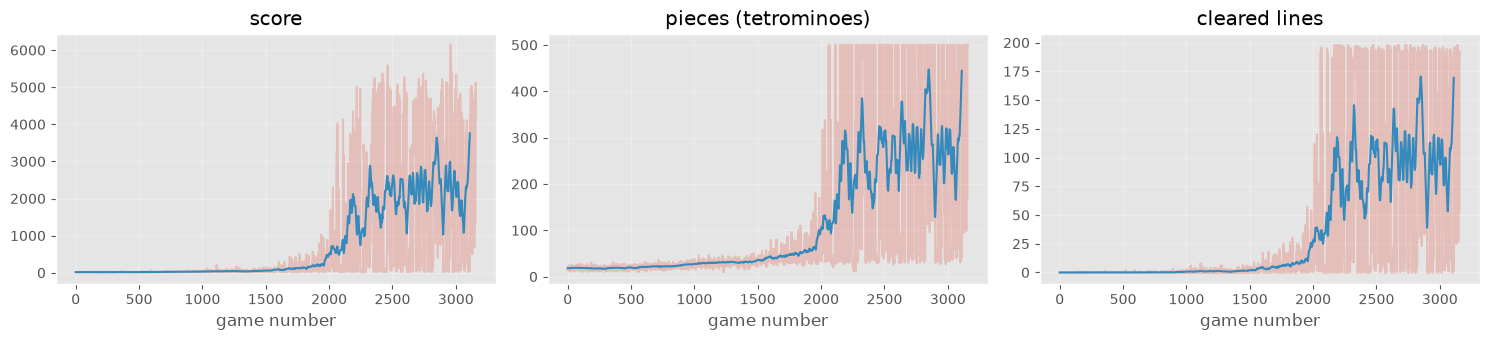

In [11]:
h = np.array(history)
window = 50
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, name in zip(axes, (1, 2, 3), ("score", "pieces (tetrominoes)", "cleared lines")):
    ax.plot(h[:, col], alpha=0.25)
    ax.plot(np.convolve(h[:, col], np.ones(window) / window, mode="valid"))
    ax.set_title(name)
    ax.set_xlabel("game number")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 📈 Reading the training curves

**What you see.** Each light line is one game. The dark line is the average of the last 50 games.
The first about 150 games only fill the replay memory (no training). After that, 1 game = 1 training step.
In our test run (seed 123), the curves stayed near 20 pieces until about game 1500. They went up fast near game 2000.
After that they jumped between about 100 and 450 pieces.

**Why the curves are flat at the start.** Epsilon is high, so most moves are random. A random agent places about 20 pieces (Lesson 1).
The network learns in this time, but the random moves hide what it knows.

**Why the curves go up.** Near game 2000, epsilon is almost 0, so the network chooses almost every move.
Better moves → longer games → better experience in the replay memory → a better network. This loop makes the fast rise.

**Why the curves go down again.** There are 3 causes:
1. **Luck.** The order of the pieces is random. A bad order can end a good game early. That is why the light line jumps from 20 to 500.
2. **DQN instability.** Each training step changes the network, and the network makes its own targets (bootstrapping).
   A good network can become worse after some updates.
3. **Bad habits.** When the agent uses a bad habit, the replay memory fills with that habit for some time.

**Why the light line stops at 500 pieces (about 200 lines).** The limit `max_pieces=500` stops the game.
The chart cannot show an agent that is better than this limit.

**Why the score curve looks like the lines curve.** The score is the sum of the rewards: +1 for each piece, and N²×10 for a move that clears N lines.
The lines part is much larger, so the two curves have the same shape.

**What it gives the agent.** Each extra piece gives +1, and each cleared line gives at least +10. So a longer game gives much more reward.
The network learns to make this sum large. The agent never sees this chart: the chart is for you.
It tells you if the training works, and when to stop.

**What we learn from the chart.**
- Learning shows only after exploration stops. Compare with the epsilon chart of Lesson 2.
- The curve still goes up at game 3000, so the training did not finish.
- The last network is not always the best one. In our test run, the last 20 games averaged 463 pieces, but the test in Part 7 gave 261 pieces.
- One game tells little. Look at averages, and test with many games.

**How to improve the training.** Change one thing at a time, train again, and compare the curves.

| Idea | Problem that it fixes | How |
|---|---|---|
| Train longer | the curve still goes up | `num_epochs=5000` in `HP` (about 2× the time) |
| Keep the best network | the last network can be worse | every 250 steps, test with ε = 0 and save the network if it is the best so far |
| Target network | instability | make the targets with a frozen copy of the network, and copy the weights every 500 steps |
| Smaller learning rate | large jumps at the end | `lr=1e-4`, or decrease it with `torch.optim.lr_scheduler` |
| Slower epsilon decay | exploration stops too early | `num_decay_epochs=2500` in `HP` |
| Move reward in the choice | the choice ignores the reward of the move | choose `argmax(reward + γ × value)` (Part 10) |
| More seeds | one run can be lucky or unlucky | train with 3 seeds and compare the averages |

Part 10 tests the idea "move reward in the choice". The first 2 ideas are also easy. The target network is the most important change in the DQN paper (2015).

---

**🇻🇳 📈 Đọc đường cong huấn luyện**

**Bạn thấy gì.** Mỗi đường nhạt là một ván. Đường đậm là trung bình của 50 ván gần nhất.
Khoảng 150 ván đầu chỉ để làm đầy bộ nhớ phát lại (chưa huấn luyện). Sau đó, 1 ván = 1 bước huấn luyện.
Trong lần chạy thử của chúng tôi (seed 123), các đường cong ở gần 20 mảnh cho đến khoảng ván 1500. Chúng đi lên nhanh gần ván 2000.
Sau đó chúng nhảy lên xuống trong khoảng 100 đến 450 mảnh.

**Tại sao lúc đầu đường cong nằm ngang.** Epsilon còn cao, nên hầu hết nước đi là ngẫu nhiên. Agent ngẫu nhiên đặt khoảng 20 mảnh (Bài 1).
Mạng vẫn học trong thời gian này, nhưng nước đi ngẫu nhiên che mất những gì nó biết.

**Tại sao đường cong đi lên.** Gần ván 2000, epsilon gần bằng 0, nên mạng chọn gần như mọi nước đi.
Nước đi tốt hơn → ván dài hơn → kinh nghiệm tốt hơn trong bộ nhớ phát lại → mạng tốt hơn. Vòng lặp này tạo ra đoạn tăng nhanh.

**Tại sao đường cong lại đi xuống.** Có 3 nguyên nhân:
1. **May rủi.** Thứ tự các mảnh là ngẫu nhiên. Một thứ tự xấu có thể kết thúc sớm một ván tốt. Vì vậy đường nhạt nhảy từ 20 lên 500.
2. **DQN không ổn định.** Mỗi bước huấn luyện thay đổi mạng, và mạng tự tạo mục tiêu cho chính nó (bootstrapping).
   Một mạng tốt có thể trở nên tệ hơn sau vài lần cập nhật.
3. **Thói quen xấu.** Khi agent dùng một thói quen xấu, bộ nhớ phát lại chứa đầy thói quen đó trong một thời gian.

**Tại sao đường nhạt dừng ở 500 mảnh (khoảng 200 hàng).** Giới hạn `max_pieces=500` dừng ván chơi.
Biểu đồ không thể cho thấy một agent tốt hơn giới hạn này.

**Tại sao đường điểm giống đường số hàng.** Điểm là tổng các phần thưởng: +1 cho mỗi mảnh, và N²×10 cho nước đi xóa N hàng.
Phần của hàng lớn hơn nhiều, nên hai đường có cùng hình dạng.

**Nó cho agent điều gì.** Mỗi mảnh thêm cho +1, và mỗi hàng xóa được cho ít nhất +10. Vì vậy ván dài hơn cho nhiều phần thưởng hơn rất nhiều.
Mạng học cách làm cho tổng này lớn. Agent không bao giờ nhìn biểu đồ này: biểu đồ dành cho bạn.
Nó cho bạn biết việc huấn luyện có hiệu quả không, và khi nào nên dừng.

**Ta học được gì từ biểu đồ.**
- Việc học chỉ hiện ra sau khi khám phá dừng lại. So sánh với biểu đồ epsilon ở Bài 2.
- Đường cong vẫn đi lên ở ván 3000, nên việc huấn luyện chưa xong.
- Mạng cuối cùng không phải lúc nào cũng tốt nhất. Trong lần chạy thử, 20 ván cuối trung bình 463 mảnh, nhưng bài kiểm tra ở Phần 7 chỉ cho 261 mảnh.
- Một ván cho biết rất ít. Hãy nhìn giá trị trung bình, và kiểm tra với nhiều ván.

**Cách cải thiện việc huấn luyện.** Mỗi lần chỉ thay đổi một thứ, huấn luyện lại, và so sánh các đường cong.

| Ý tưởng | Vấn đề nó sửa | Cách làm |
|---|---|---|
| Huấn luyện lâu hơn | đường cong vẫn đi lên | `num_epochs=5000` trong `HP` (khoảng gấp 2 thời gian) |
| Giữ mạng tốt nhất | mạng cuối có thể tệ hơn | cứ 250 bước, kiểm tra với ε = 0 và lưu mạng nếu nó tốt nhất từ trước đến giờ |
| Mạng mục tiêu (target network) | không ổn định | tạo mục tiêu bằng một bản sao "đóng băng" của mạng, và sao chép trọng số mỗi 500 bước |
| Tốc độ học nhỏ hơn | nhảy lớn ở cuối | `lr=1e-4`, hoặc giảm dần bằng `torch.optim.lr_scheduler` |
| Giảm epsilon chậm hơn | khám phá dừng quá sớm | `num_decay_epochs=2500` trong `HP` |
| Thêm phần thưởng vào lựa chọn | lựa chọn bỏ qua phần thưởng của nước đi | chọn `argmax(reward + γ × value)` (Phần 10) |
| Nhiều seed hơn | một lần chạy có thể may hoặc rủi | huấn luyện với 3 seed và so sánh trung bình |

Phần 10 thử ý tưởng "thêm phần thưởng vào lựa chọn". 2 ý tưởng đầu cũng dễ. Mạng mục tiêu là thay đổi quan trọng nhất trong bài báo DQN (2015).

**Check:** find the game where the dark line starts to go up in your chart. What was epsilon then? (See the log of Part 5.)

## Part 7 — Test your agent

No exploration now: the agent always takes the best move.

---

🇻🇳 **Kiểm tra:** tìm ván mà đường đậm bắt đầu đi lên trong biểu đồ của bạn. Lúc đó epsilon bằng bao nhiêu? (Xem log của Phần 5.)

**🇻🇳 Phần 7 — Kiểm tra agent của bạn**

Bây giờ không còn khám phá: agent luôn chọn nước đi tốt nhất.

In [12]:
model.eval()
print(f"{'random':<20}", evaluate(random_policy, games=5, max_pieces=500))
print(f"{'your network':<20}", evaluate(greedy_policy(model), games=5, max_pieces=500))
try:
    print(f"{'pre-trained (author)':<20}", evaluate(greedy_policy(load_model('trained_models/tetris')), games=5, max_pieces=500))
except RuntimeError as error:
    print("pre-trained model not available:", str(error).splitlines()[0])

random               {'pieces': 19.4, 'lines': 0.0, 'score': 17.4}
your network         {'pieces': 261.0, 'lines': 91.2, 'score': 2219.4}
pre-trained (author) {'pieces': 325.6, 'lines': 116.8, 'score': 2636.0}


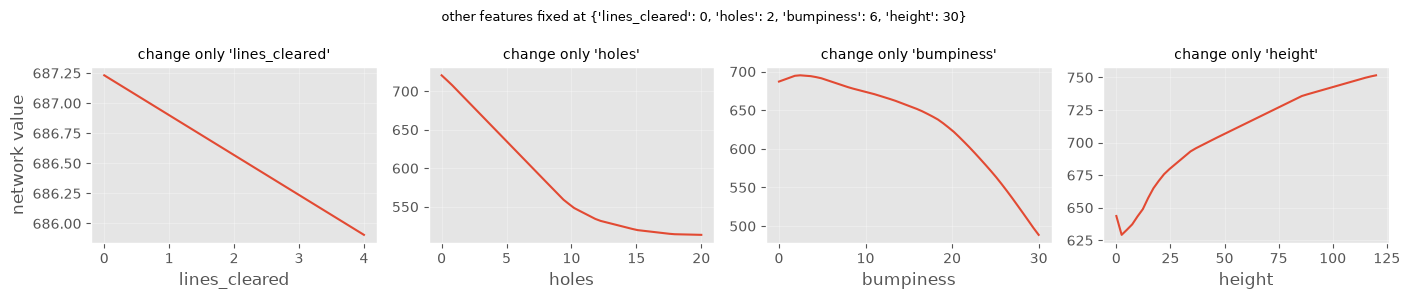

In [13]:
feature_sweep(model)

### 📈 Reading the chart: your network

- Compare it with the chart in Lesson 2, Part 5. In our test run, the shapes were almost the same:
  holes and bumpiness go down, height goes up, and `lines_cleared` is almost flat.
  Two networks that trained separately found the same "taste".
- The numbers are different (for example about 690 here and 770 for the author's network). That is not important:
  the agent compares only the values of the afterstates of the same board.
- If your curves look very different (for example the value goes up with holes), your network did not train enough,
  or the training stopped at a bad moment. Train longer, or keep the best network (the table in Part 6).

---

**🇻🇳 📈 Đọc biểu đồ: mạng của bạn**

- So sánh với biểu đồ ở Bài 2, Phần 5. Trong lần chạy thử của chúng tôi, các hình dạng gần như giống nhau:
  lỗ và độ gồ ghề làm giá trị giảm, chiều cao làm giá trị tăng, và `lines_cleared` gần như nằm ngang.
  Hai mạng được huấn luyện riêng đã tìm ra cùng một "khẩu vị".
- Các con số khác nhau (ví dụ khoảng 690 ở đây và 770 ở mạng của tác giả). Điều đó không quan trọng:
  agent chỉ so sánh giá trị của các afterstate từ cùng một bàn chơi.
- Nếu đường cong của bạn rất khác (ví dụ giá trị tăng khi số lỗ tăng), mạng của bạn chưa huấn luyện đủ,
  hoặc việc huấn luyện dừng ở một thời điểm xấu. Hãy huấn luyện lâu hơn, hoặc giữ mạng tốt nhất (bảng ở Phần 6).

## Part 8 — Save your model and watch it play

We save to `my_models/`, so the model of the author in `trained_models/` does not change.

---

**🇻🇳 Phần 8 — Lưu mô hình và xem nó chơi**

Ta lưu vào `my_models/`, để mô hình của tác giả trong `trained_models/` không bị thay đổi.

In [ ]:
os.makedirs("my_models", exist_ok=True)
torch.save(model, "my_models/tetris")
print("saved: my_models/tetris")

To watch your agent in a window, run this in a terminal:

```
uv run python test.py --saved_path my_models
```

---

🇻🇳 Để xem agent của bạn chơi trong cửa sổ, chạy lệnh ở trên trong terminal.

## Part 9 — More experiments

Change one thing, run Part 5 again, and compare the curves. Write down your results.

1. `gamma=0.5`: the agent becomes "short-sighted". What happens to the cleared lines?
2. `num_decay_epochs=200`: the agent stops exploring early. Is the final result worse?
3. `batch_size=32`: smaller batches. Is training less stable?
4. Remove the `holes` feature: in `src/tetris.py` line 87 and in `src/deep_q_network.py` line 10 (`Linear(3, 64)`).

---

**🇻🇳 Phần 9 — Thêm thí nghiệm**

Thay đổi một thứ, chạy lại Phần 5, và so sánh các đường cong. Ghi lại kết quả của bạn.

1. `gamma=0.5`: agent trở nên "thiển cận". Số hàng xóa được thay đổi thế nào?
2. `num_decay_epochs=200`: agent ngừng khám phá sớm. Kết quả cuối có tệ hơn không?
3. `batch_size=32`: lô nhỏ hơn. Huấn luyện có kém ổn định hơn không?
4. Bỏ đặc trưng `holes`: trong `src/tetris.py` dòng 87 và trong `src/deep_q_network.py` dòng 10 (`Linear(3, 64)`).

## Part 10 — Experiment: add the move reward to the choice

In Part 5 (and in `train.py`) the agent chooses the afterstate with the highest **value**: `argmax V(afterstate)`.
But the value of an afterstate holds only the rewards that come **after** it.
The reward of the move itself (+1, plus 10 for 1 line, up to 161 for 4 lines) is not part of the choice.
(Lesson 2, Part 5: that is why `lines_cleared` has almost no effect on the value.)

The usual rule for afterstate values adds this reward:

```
choice = argmax( reward(move) + γ × V(afterstate) )      with reward(move) = 1 + lines² × 10
```

The agent can calculate the reward before the move, because `lines_cleared` is the first feature of each afterstate.
Only the choice changes. The memory, the Bellman target and the loss stay the same.

- `train_dqn()` in `notebooks/reward_lab.py` is the loop of Part 5 as a function. It has the option `use_move_reward=True`.
- The test uses the same rule: `greedy_policy(model_mr, use_move_reward=True)`.

**Before you run:** do you expect a better agent, a worse agent, or no change? Why?

⏱ About 7 minutes: longer than Part 5, because the better agent plays longer games. The comparison uses `model` and `history` from Part 5. If you changed Part 5 in Part 9, run it again first.

---

**🇻🇳 Phần 10 — Thí nghiệm: thêm phần thưởng của nước đi vào lựa chọn**

Ở Phần 5 (và trong `train.py`), agent chọn afterstate có **giá trị** cao nhất: `argmax V(afterstate)`.
Nhưng giá trị của một afterstate chỉ chứa những phần thưởng đến **sau** nó.
Phần thưởng của chính nước đi đó (+1, cộng 10 cho 1 hàng, đến 161 cho 4 hàng) không nằm trong lựa chọn.
(Bài 2, Phần 5: đó là lý do `lines_cleared` gần như không ảnh hưởng đến giá trị.)

Quy tắc thông thường cho giá trị afterstate cộng thêm phần thưởng này:

```
lựa chọn = argmax( reward(nước đi) + γ × V(afterstate) )      với reward(nước đi) = 1 + lines² × 10
```

Agent tính được phần thưởng trước khi đi, vì `lines_cleared` là đặc trưng đầu tiên của mỗi afterstate.
Chỉ có lựa chọn thay đổi. Bộ nhớ, mục tiêu Bellman và hàm mất mát giữ nguyên.

- `train_dqn()` trong `notebooks/reward_lab.py` là vòng lặp của Phần 5 dưới dạng hàm. Nó có tùy chọn `use_move_reward=True`.
- Bài kiểm tra dùng cùng quy tắc: `greedy_policy(model_mr, use_move_reward=True)`.

**Trước khi chạy:** bạn nghĩ agent sẽ tốt hơn, tệ hơn hay không thay đổi? Tại sao?

⏱ Khoảng 7 phút: lâu hơn Phần 5, vì agent tốt hơn chơi những ván dài hơn. Phép so sánh dùng `model` và `history` từ Phần 5. Nếu bạn đã sửa Phần 5 ở Phần 9, hãy chạy lại nó trước.

In [ ]:
from reward_lab import REWARDS, train_dqn

# The same reward, settings and seed as Part 5. Only the choice rule changes.
model_mr, history_mr = train_dqn(REWARDS["author: 1 + N²×w"], HP, seed=123, log_every=250,
                                 use_move_reward=True)

In [ ]:
window = 50
old, new = np.array(history), np.array(history_mr)     # old: (epoch, score, pieces, lines), new: (epoch, pieces, lines)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (col_old, col_new, name) in zip(axes, ((2, 1, "pieces"), (3, 2, "cleared lines"))):
    ax.plot(np.convolve(old[:, col_old], np.ones(window) / window, mode="valid"), label="argmax(value)  (Part 5)")
    ax.plot(np.convolve(new[:, col_new], np.ones(window) / window, mode="valid"), label="argmax(reward + γ·value)")
    ax.set_title(f"{name} per game (average of {window} games)")
    ax.set_xlabel("game number")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'argmax(value)':<26}", evaluate(greedy_policy(model), games=5, max_pieces=500))
print(f"{'argmax(reward + γ·value)':<26}", evaluate(greedy_policy(model_mr, use_move_reward=True), games=5, max_pieces=500))

### 📈 Reading the result

Our test runs: 3 seeds for each rule, the settings of Part 5, and 5 test games with a limit of 500 pieces.

| Seed | `argmax(value)`: pieces / lines | `argmax(reward + γ·value)`: pieces / lines |
|---|---|---|
| 123 | 261 / 91 | 500 / 197 |
| 7 | 175 / 55 | 500 / 197 |
| 42 | 500 / 196 | 409 / 154 |
| **average lines** | **114** | **183** |

In the last 200 training games, the new rule cleared 153–159 lines per game. The old rule cleared 89–109.
The dark line of the new rule reached the limit of 500 pieces with all 3 seeds. The old rule reached 401–483.

**What we learn.**
- The new rule was better at the end of training with all 3 seeds, and better in the test with 2 of 3 seeds.
  Seed 42 shows again that one test can be lucky or unlucky.
- With both rules, the curves start to go up at about the same game (near game 2000), because epsilon decides when the learning shows.
  The difference comes after that: the new rule climbs higher and stays higher.
- **Why it helps.** The old rule compares only the future of each board, so it does not see the reward of a line clear.
  The new rule sees this reward now, so it takes the clears that the old rule missed.
  Its choice is also the same quantity as the target that the network learns: `reward + γ × V(next_state)`.
- A small change in the decision rule changed the result more than many changes of the settings.
  Read the code of a method carefully: sometimes the improvement is a missing term.

**Try it:** run both rules with another seed (`seed=2024` in `train_dqn` and in Part 5). Does the new rule win again?

---

**🇻🇳 📈 Đọc kết quả**

Các lần chạy thử của chúng tôi: mỗi quy tắc 3 seed, thiết lập của Phần 5, và 5 ván kiểm tra với giới hạn 500 mảnh.

| Seed | `argmax(value)`: mảnh / hàng | `argmax(reward + γ·value)`: mảnh / hàng |
|---|---|---|
| 123 | 261 / 91 | 500 / 197 |
| 7 | 175 / 55 | 500 / 197 |
| 42 | 500 / 196 | 409 / 154 |
| **trung bình hàng** | **114** | **183** |

Trong 200 ván huấn luyện cuối, quy tắc mới xóa 153–159 hàng mỗi ván. Quy tắc cũ xóa 89–109.
Đường đậm của quy tắc mới đạt giới hạn 500 mảnh với cả 3 seed. Quy tắc cũ đạt 401–483.

**Ta học được gì.**
- Quy tắc mới tốt hơn ở cuối quá trình huấn luyện với cả 3 seed, và tốt hơn trong bài kiểm tra với 2 trên 3 seed.
  Seed 42 cho thấy lại rằng một bài kiểm tra có thể may hoặc rủi.
- Với cả hai quy tắc, đường cong bắt đầu đi lên ở gần cùng một ván (gần ván 2000), vì epsilon quyết định khi nào việc học hiện ra.
  Khác biệt đến sau đó: quy tắc mới leo cao hơn và giữ ở mức cao hơn.
- **Tại sao nó giúp ích.** Quy tắc cũ chỉ so sánh tương lai của mỗi bàn chơi, nên nó không thấy phần thưởng của một lần xóa hàng.
  Quy tắc mới thấy phần thưởng này ngay, nên nó chọn những lần xóa hàng mà quy tắc cũ bỏ lỡ.
  Lựa chọn của nó cũng chính là đại lượng mà mạng học làm mục tiêu: `reward + γ × V(next_state)`.
- Một thay đổi nhỏ trong quy tắc ra quyết định thay đổi kết quả nhiều hơn nhiều thay đổi về thiết lập.
  Hãy đọc kỹ code của một phương pháp: đôi khi cải tiến chính là một thành phần bị thiếu.

**Thử xem:** chạy cả hai quy tắc với một seed khác (`seed=2024` trong `train_dqn` và trong Phần 5). Quy tắc mới có thắng lần nữa không?

### The full `train.py`

```
mkdir -p my_models
uv run python train.py --saved_path my_models
uv run tensorboard --logdir tensorboard
```

⚠️ Always use `--saved_path my_models`. With the default path, `train.py` overwrites the model of the author in `trained_models/tetris`.
`train.py` draws every move in a window, so it is much slower than this notebook.

## Summary

- The agent stores transitions `[state, reward, next_state, done]` in a replay memory.
- Each training step: take 512 random transitions, make the Bellman targets, calculate the MSE loss, do one Adam step.
- Epsilon goes down, so the agent explores first and uses its knowledge later.
- We measure progress with game results (score, pieces, lines), not with the loss.

**Next:** `04_reward_lab.ipynb` — how the reward function changes what the agent learns.

### Next topics to study

- **Target network:** a frozen copy of the network makes the targets more stable (original DQN, 2015).
- **Double DQN:** reduces the habit of DQN to over-estimate values.
- **Raw board input:** give the 200 cells to a convolution network, and let it discover its own features.

---

**🇻🇳 Chạy toàn bộ `train.py`:** dùng các lệnh ở trên.

⚠️ Luôn dùng `--saved_path my_models`. Với đường dẫn mặc định, `train.py` ghi đè mô hình của tác giả trong `trained_models/tetris`.
`train.py` vẽ mọi nước đi trong cửa sổ, nên chậm hơn notebook này rất nhiều.

**🇻🇳 Tóm tắt**

- Agent lưu các transition `[state, reward, next_state, done]` trong bộ nhớ phát lại.
- Mỗi bước huấn luyện: lấy 512 transition ngẫu nhiên, tạo mục tiêu Bellman, tính loss MSE, chạy một bước Adam.
- Epsilon giảm dần, nên agent khám phá trước và dùng kiến thức của nó sau.
- Ta đo tiến bộ bằng kết quả chơi (điểm, số mảnh, số hàng), không bằng loss.

**Tiếp theo:** `04_reward_lab.ipynb` — hàm phần thưởng thay đổi những gì agent học được.

**🇻🇳 Chủ đề nên học tiếp**

- **Target network (mạng mục tiêu):** một bản sao "đóng băng" của mạng giúp mục tiêu ổn định hơn (DQN gốc, 2015).
- **Double DQN:** giảm thói quen ước lượng giá trị quá cao của DQN.
- **Đầu vào là bàn chơi thô:** đưa 200 ô vào một mạng tích chập (convolution) và để nó tự khám phá đặc trưng.